# 各个包 to 配置

In [27]:
"""
MedicalGMU + X-ray + Clinical Tabular
- 影像(ResNet18)主导分类，临床特征仅做门控调制(GMU)
- 支持多任务辅助监督(aux_label)帮助影像学习形态特征
- 必须按病人(Group)划分训练/验证
"""

import os
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18

from sklearn.model_selection import KFold

current_dir = Path.cwd() #ipynb相当于cmd环境
root_dir = current_dir.parent 
# print(root_dir)
text_path = root_dir / 'data' / 'raw' / 'tabular_data.xlsx'
pkl_path =  root_dir / 'data' / 'interim' 
image_root = root_dir / 'data'  / 'raw'/ 'image' 
resnet_weight = root_dir / 'weights' / 'resnet18.pth'
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
# device = torch.device("cuda:0")  
# weights = torch.tensor([1.0, 2.6132]).to(device)
# ========== 配置 ==========
CONFIG = {
	'excel_path': text_path,          # 包含 patient_id + feature_cols + aux_cols
	 'pkl_path': pkl_path / 'clinical.pkl', 
	'image_root': image_root,               # 病人影像根目录
	'save_dir':  root_dir/ 'notebooks'/'result'/'AGMU',
  'checkpoint_dir': root_dir/ 'notebooks'/'result'/'AGMU',
	'img_size': 224,
	'batch_size': 8,                            # 医学影像显存占用大，建议8-16
	'epochs': 100,
	'lr_backbone': 1e-5,                       # 影像backbone小学习率微调
	'lr_head': 1e-3,                           # 临床塔/分类头大学习率
	'weight_decay': 1e-4,
	'dropout': 0.4,
	'patience': 20,
	'use_aux_task': True,                      # 是否用 aux_label 做多任务辅助
	'aux_weight': 0.3,                         # 辅助损失权重
	'pos_weight': 3,                         # III型(正类)加权
	'seed': 42,
	'device': torch.device("cuda:0") ,
	'resnet_weight':resnet_weight,
  'threshold': 0.25,  
}

os.makedirs(CONFIG['save_dir'], exist_ok=True)
torch.manual_seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])

# Multi-Modal DATASET

## 预处理

In [5]:
# ========== 1. 数据预处理（生成 clinical.pkl） ==========

def preprocess_and_save(excel_path, pkl_path):
	df = pd.read_excel(excel_path, header=1, nrows=280)
	df.columns = df.columns.str.strip()


	df_sorted = df.sort_values(by=['编号', '关节形态'], ascending=[True, False])
	patient_level =df.groupby('编号')['关节形态'].max().reset_index()
	# grouped = df.groupby('编号')
	# for patient_id, group_data in grouped:
	# 	print(f"=== 编号: {patient_id} 的分组 ===")
	# 	print(group_data)
	# 	print("----------------")
	# clinical_data = df.drop_duplicates(subset=['编号'], keep='first').copy()
	clinical_data = df_sorted.drop_duplicates(subset=['编号'], keep='first').copy()
	clinical_data = clinical_data.drop(columns= ['关节形态'])
	df = pd.merge(clinical_data, patient_level, on='编号')
	df['关节形态'] = df['关节形态'].apply(lambda x: 1 if x == 3 else 0)
	print(df.head())

	print(len(df))
	print(df.columns)
	data = pd.DataFrame()
	data['patient_id'] = df['编号'].astype(str).str.strip()
	# Categorical features (for Embedding)
	data['has_syrinx'] = df['合并脊髓空洞'].map({'是': 1, '有': 1, '否': 0, '无': 0}).fillna(0).astype(int)
	scale2_map = {'无痛': 0, '轻度疼痛': 1, '中度疼痛': 2, '重度疼痛': 3}
	data['scale2_1'] = df['疼痛分级'].map(scale2_map).fillna(0).astype(int)
	data['scale2_2'] = df['疼痛分级.1'].map(scale2_map).fillna(0).astype(int)
	data['scale2_3'] = df['疼痛分级.2'].map(scale2_map).fillna(0).astype(int)
	data['age']= df['年龄'].fillna(0).astype(int)
	data['gender']=df['性别'].map({'男': 1, '女': 0}).fillna(0).astype(int)
	asa_map = {'I': 0, 'II': 1, 'III': 2, 'IV': 3}
	data['asa']=df['ASA分级'].map(asa_map).fillna(0).astype(int)
	# Continuous features (for StandardScaler)
	data['syrinx_num'] = pd.to_numeric(df['脊髓空洞节段数量'], errors='coerce').fillna(0)
	data['syrinx_wide'] = pd.to_numeric(df['脊髓空洞最大宽度（只计算有空洞的）'], errors='coerce').fillna(0)
	data['CTH'] = pd.to_numeric(df['小脑扁桃体疝出程度'], errors='coerce').fillna(0)
	
	cisterna = pd.to_numeric(df['枕大池容积'], errors='coerce')
	# cisterna_max = cisterna.max()
	data['cisterna_flipped'] = (-cisterna).fillna(0)
	
	data['scale1'] = pd.to_numeric(df['量表1总分'], errors='coerce').fillna(0)
	data['scale3'] = pd.to_numeric(df['术前量表3总分'], errors='coerce').fillna(100)  # ADL，缺失=满分
	joa = pd.to_numeric(df['术前量表4总分'], errors='coerce')
	data['joa_flipped'] = (17 - joa).fillna(0)

	# 保存（标签从影像文件夹解析，这里不存label）
	data.to_pickle(pkl_path)
	print(f"[Preprocess] Saved clinical features to {pkl_path}")
	return data


In [6]:
data = preprocess_and_save(CONFIG['excel_path'], CONFIG['pkl_path'])
print(data)

   编号  年龄 性别                                       主诉      主诊断  \
0   1  29  男  枕颈部酸胀痛、四肢疼痛伴双眼复视1年,加重伴四肢乏力、行走不稳、尿频尿急2月。  II型颅底凹陷   
1   2  49  男                         双上肢乏力、麻木2年，伴便秘2周  II型颅底凹陷   
2   3  18  女                    颈部疼痛伴头痛7月余，加重伴行走不稳1月。  II型颅底凹陷   
3   4  67  女         头痛、右侧前臂及腰背部痛9月,件右手麻木、下肢乏力、行走缓慢3月  II型颅底凹陷   
4   5  32  女   颈枕部及右侧肢体胀痛，右侧肢体麻木乏力4月,上行性加重伴便秘、尿频尿急3月。  II型颅底凹陷   

                                                伴随诊断 既往疾病 既往手术史 既往过敏史  \
0  侧裂区蛛网膜囊肿(左侧)、颈椎间盘突出(C4/5和C6/7中央型突出,C5/6膨隆)、颈椎退行性变    无     无     无   
1             髓空洞症(C2-C6)、寰枕融合畸形、颈椎半脱位(C1/2左侧侧方关节)\n    无     无     无   
2                      :寰枢椎脱位、脊髓受压((延髓和上颈髓受压))上颌窦炎\n    无     无     无   
3                                       脊髓空洞症、寰枕融合畸形    无     无     无   
4                              脊髓空洞症、寰枢椎脱位、颈椎退行性病变\n    无     无     无   

                                              关节形态.1  ... 术前量表3总分比值    量表3分级  \
0  枕骨髁变成明显扁平且整体瘦小的骨骼形态；寰椎侧块严重畸形，上关节面的深度和曲率明显下降，前后...  ...       8.0   轻度功能障碍   
1  枕

# s数据集

In [7]:
class ChiariXrayDataset(Dataset):
	def __init__(self, pkl_path, image_root, patient_ids, transform=None,
				 scaler=None, fit_scaler=False):
		"""
		patient_ids: 当前Fold的病人ID列表（str）
		"""
		self.root_dir = Path(image_root)
		self.transform = transform
		self.samples = []

		# 加载临床表格
		df = pd.read_pickle(pkl_path)
		print(len(df))
		df['patient_id'] = df['patient_id'].astype(str).str.strip()
		df_indexed = df.set_index('patient_id')
		# print(df_indexed)
		# 特征列定义（与你上传的代码严格一致）
		self.cat_cols = ['has_syrinx', 'scale2_1', 'scale2_2', 'scale2_3','gender','asa']
		self.cont_cols = ['syrinx_num', 'syrinx_wide', 'CTH',
							'cisterna_flipped', 'scale1', 'scale3', 'joa_flipped','age']

		# Continuous 标准化（仅训练集fit）
		if fit_scaler:
			self.scaler = StandardScaler()
			df[self.cont_cols] = self.scaler.fit_transform(df[self.cont_cols])
		else:
			self.scaler = scaler
			if scaler is not None:
				df[self.cont_cols] = scaler.transform(df[self.cont_cols])

		# 遍历指定病人，解析影像文件夹
		for p_id in patient_ids:
			p_id_str = str(p_id).strip()
			if p_id_str not in df_indexed.index:
				continue

			row = df_indexed.loc[p_id_str]

			# Categorical: dict of int scalars
			cat_dict = {c: int(row[c]) for c in self.cat_cols}
			# Continuous: numpy array -> tensor
			cont_arr = row[self.cont_cols].values.astype(float)

			patient_folder = self.root_dir / p_id_str
			if not patient_folder.is_dir():
				continue

			# 遍历左右关节
			for side_folder in patient_folder.iterdir():
				if not side_folder.is_dir():
					continue
				folder_name = side_folder.name

				side = 'left' if '左' in folder_name else 'right'

				# 标签从文件夹名解析（3型/III型 = 1）
				if '3型' in folder_name or 'III型' in folder_name:
					label = 1
				else:
					label = 0

				# 遍历该关节下所有影像
				for img_file in side_folder.glob('*.*'):
					if img_file.suffix.lower() in ['.png', '.jpg', '.jpeg', '.tif', '.tiff']:
						self.samples.append({
							'path': str(img_file),
							'label': label,
							'patient_id': p_id_str,
							'side': side,
							'cat_dict': cat_dict,      # dict of ints
							'cont_arr': cont_arr.copy()  # float array
						})

		print(f"[Dataset] 病人: {len(set(s['patient_id'] for s in self.samples))}, "
				f"影像: {len(self.samples)}, "
				f"正类(III型): {sum(s['label'] for s in self.samples)}")

	def __len__(self):
		return len(self.samples)

	def __getitem__(self, idx):
		s = self.samples[idx]
		img = Image.open(s['path']).convert('L')
		if self.transform:
			img = self.transform(img)

		label = torch.tensor(s['label'], dtype=torch.long)

		# Categorical: dict of tensors (for Embedding)
		cat_features = {
			k: torch.tensor(v, dtype=torch.long)
			for k, v in s['cat_dict'].items()
		}
		# Continuous: tensor (already scaled)
		cont_features = torch.tensor(s['cont_arr'], dtype=torch.float32)

		joint_id = f"{s['patient_id']}_{s['side']}"

		return img, label, cat_features, cont_features, s['patient_id'], joint_id


def collate_fn(batch):
	"""拼接 batch，处理 dict 型 categorical features"""
	imgs = torch.stack([b[0] for b in batch])
	labels = torch.stack([b[1] for b in batch])

	cat_keys = batch[0][2].keys()
	cat_batch = {k: torch.stack([b[2][k] for b in batch]) for k in cat_keys}

	cont_batch = torch.stack([b[3] for b in batch])
	patient_ids = [b[4] for b in batch]
	joint_ids = [b[5] for b in batch]

	return imgs, labels, cat_batch, cont_batch, patient_ids, joint_ids

# 模型

In [8]:
class ClinicalEncoder(nn.Module):
	"""
	临床表格编码器：
	- Categorical -> Embedding
	- Continuous -> StandardScaler后投影
	- 融合 -> 16-d 临床表示
	"""
	def __init__(self, cont_dim=8, out_dim=16):
		super().__init__()

		# 
		self.embeddings = nn.ModuleDict({
			'has_syrinx': nn.Embedding(2, 2),      # 2 classes
			'scale2_1': nn.Embedding(4, 3),         # 4 classes (0-3)
			'scale2_2': nn.Embedding(4, 3),
			'scale2_3': nn.Embedding(4, 3),
			'gender': nn.Embedding(2,2),
			'asa': nn.Embedding(4,3),		
		})
		cat_dim = 2 + 3 + 3 + 3  +3+2# 16

		self.cont_proj = nn.Sequential(
			nn.Linear(cont_dim, 16),
			nn.BatchNorm1d(16),
			nn.ReLU(),
			nn.Dropout(0.2)
		)

		self.fusion = nn.Sequential(
			nn.Linear(cat_dim + 16, out_dim),
			nn.LayerNorm(16),
			nn.Dropout(p=0.1)
		)

	def forward(self, cat_features, cont_features):
		# cat_features: dict of [B] LongTensor
		embeds = []
		for key, emb in self.embeddings.items():
			embeds.append(emb(cat_features[key]))
		cat_feat = torch.cat(embeds, dim=-1)  # [B, 11]

		cont_feat = self.cont_proj(cont_features)  # [B, 16]

		combined = torch.cat([cat_feat, cont_feat], dim=-1)  # [B, 27]
		return self.fusion(combined)  # [B, 16]



class MedicalGMUFusion(nn.Module):
	"""
	改良 GMU：
	- gate 仅由临床特征生成（非对称，防止偷懒）
	- clin_proj 把临床映射到影像维度
	- 残差 +img_feat 保证影像信息不丢失
	"""
	def __init__(self, img_dim=512, clin_dim=16):
		super().__init__()
		self.clin_proj = nn.Sequential(
			nn.Linear(clin_dim, 64),
			nn.ReLU(),
			nn.Linear(64, img_dim)
		)
		# 门控：临床 → 影像维度权重 (0,1)
		self.gate = nn.Sequential(
			nn.Linear(clin_dim, img_dim),
			nn.Sigmoid()
		)
		# 融合后投影
		self.fusion = nn.Sequential(
			nn.Linear(img_dim, img_dim),
			nn.BatchNorm1d(img_dim),
			nn.ReLU()
		)

	def forward(self, img_feat, clin_feat):
		# clin_feat: [B, clin_dim]
		c = self.clin_proj(clin_feat)   # [B, img_dim]
		z = self.gate(clin_feat)         # [B, img_dim]

		# GMU 加权：影像为主，临床补充/抑制
		fused = z * img_feat + (1.0 - z) * c
		# 残差：即使 gate≈0，影像特征仍能直通
		out = self.fusion(fused) 
		return out+ img_feat


class MedicalGMUNet(nn.Module):
	def __init__(self, num_cont=7, clin_out=16,pretrained_path = None):
		super().__init__()

		# --- 影像塔：ResNet18，单通道 X-ray ---
		self.resnet = resnet18(weights='DEFAULT')
		num_ftrs= self.resnet.fc.in_features

		self.resnet.fc = nn.Identity()
		if pretrained_path:
			self.load_smart_weights(pretrained_path)

		# --- 临床塔 ---
		self.clinical_encoder = ClinicalEncoder(cont_dim=num_cont, out_dim=clin_out)

		# --- GMU 融合 ---
		self.gmu = MedicalGMUFusion(img_dim=512, clin_dim=clin_out)

		# --- 分类头 ---
		self.classifier = nn.Sequential(
			nn.Linear(512, 2),
			# nn.BatchNorm1d(256),
			# nn.ReLU(),
			# nn.Dropout(CONFIG['dropout']),
			# nn.Linear(256, 2)
		)

		self._init_weights()

	def load_smart_weights(self, path):
		print(f"正在加载权重文件: {path}")
		state_dict = torch.load(path, map_location='cpu')
		possible_keys = ['state_dict', 'model', 'net', 'model_state_dict']
		for key in possible_keys:
			if key in state_dict and isinstance(state_dict[key], dict):
				print(f"发现权重被包裹在 '{key}' 中，正在拆包...")
				state_dict = state_dict[key]
				break
		model_state_dict = self.state_dict()
		new_state_dict = {}
		matched_layers = 0
		print(f" 开始匹配 (文件包含 {len(state_dict)} 个键)...")
		for k, v in state_dict.items():
			key_clean = k.replace('_orig_mod.', '')
			key_clean = key_clean.replace('module.', '')
			target_key = "resnet." + key_clean
			# 开始尝试匹配
			final_key = None
			if target_key in model_state_dict:
				final_key = target_key
			elif key_clean in model_state_dict:
				final_key = key_clean
			if final_key:
				if v.shape == model_state_dict[final_key].shape:
					new_state_dict[final_key] = v
					matched_layers += 1
				else:
					pass

		self.load_state_dict(new_state_dict, strict=False)
		print(f"权重加载完成！成功匹配: {matched_layers}")

		if matched_layers == 0:
				# 如果清洗了这么多还是 0，那可能是文件真的错了
				print(f" 警告：匹配数为 0！")
				print(f" 文件里的第一条Key (清洗后): {key_clean}")
				print(f"  模型里的第一条Key (预期): {list(model_state_dict.keys())[0]}")
				raise RuntimeError("无法匹配任何权重，请检查上述 Key 的差异。")


	def _init_weights(self):
		for m in self.modules():
			if isinstance(m, nn.Linear):
				nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
				if m.bias is not None:
					nn.init.zeros_(m.bias)
			elif isinstance(m, nn.Embedding):
				nn.init.normal_(m.weight, std=0.1)

	def forward(self, img, cat_features, cont_features):
		# img: [B, 1, H, W]
		img_feat = self.resnet(img)  # [B, 512]

		clin_feat = self.clinical_encoder(cat_features, cont_features)  # [B, 16]
		fused = self.gmu(img_feat, clin_feat)  # [B, 512]

		logits = self.classifier(fused)  # [B]
		return logits

# 数据增强

In [9]:
def get_transforms(phase='train', img_size=512):
	if phase == 'train':
		return transforms.Compose([
			transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
			transforms.ColorJitter(brightness=0.3, contrast=0.3), # 强化骨骼边缘对比度
			transforms.Grayscale(num_output_channels=3),
			transforms.RandomRotation(degrees=5),
			transforms.RandomAffine(degrees=0, translate=(0.02, 0.02)),
			transforms.ToTensor(),
			transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
		])
	else:
		return transforms.Compose([
			transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
			transforms.Grayscale(num_output_channels=3),
			transforms.ToTensor(),
			transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
		])


def find_best_threshold(y_true, y_prob):
	"""基于约登指数找最优阈值"""
	best_youden = -1
	best_thresh = 0.5
	for t in np.arange(0.05, 1.0, 0.05):
		y_pred = (np.array(y_prob) >= t).astype(int)
		try:
			tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
			sens = tp / (tp + fn) if (tp + fn) > 0 else 0
			spec = tn / (tn + fp) if (tn + fp) > 0 else 0
			youden = sens + spec - 1
			if youden > best_youden:
				best_youden = youden
				best_thresh = t
		except ValueError:
			continue
	return best_thresh

# 评价函数

In [10]:
from sklearn.metrics import (
	roc_auc_score, roc_curve, accuracy_score, 
	precision_score, recall_score, f1_score, 
	average_precision_score, confusion_matrix
)

## joint-level

In [11]:
from collections import defaultdict
from sklearn.metrics import (
	accuracy_score, precision_score, recall_score, 
	f1_score, roc_auc_score, confusion_matrix, average_precision_score,
)

@torch.no_grad()
def evaluate_joint_level(model, dataloader, device, search_threshold=False,best_t=0.25):
	"""
	关节级评估：同一个 joint_id（如 001_left）的多张影像概率取平均。
	
	Args:
		search_threshold: 是否基于约登指数搜索最优阈值。False 则用 0.5。
	"""
	model.eval()
	joint_probs = defaultdict(list)   # {joint_id: [prob_img1, prob_img2, ...]}
	joint_labels = {}                # {joint_id: label}

	for imgs, labels, cat_batch, cont_batch, _, joint_ids in dataloader:
		imgs = imgs.to(device)
		cat_batch = {k: v.to(device) for k, v in cat_batch.items()}
		cont_batch = cont_batch.to(device)

		logits = model(imgs, cat_batch, cont_batch)

		# ========== 兼容两种输出格式 ==========
		if logits.dim() == 1 or logits.size(-1) == 1:
			# 单输出 [B] 或 [B,1] → sigmoid
			probs = torch.sigmoid(logits).cpu().numpy()
			if probs.ndim == 2:
				probs = probs.squeeze(-1)
		else:
			# 双输出 [B, 2] → softmax 取第1类（III型）
			probs = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()

		# 收集每个关节的概率
		for i in range(len(joint_ids)):
			jid = joint_ids[i]
			joint_probs[jid].append(float(probs[i]))
			# 同一个关节的 label 肯定相同，重复赋值无妨
			joint_labels[jid] = int(labels[i].item())
			

	# ========== 聚合：每个关节平均概率 ==========
	final_labels, final_probs = [], []
	final_joint_ids = []

	for jid in sorted(joint_probs.keys()):
		avg_prob = np.mean(joint_probs[jid])
		final_probs.append(avg_prob)
		final_labels.append(joint_labels[jid])
		final_joint_ids.append(jid)
		

	final_labels = np.array(final_labels)
	final_probs = np.array(final_probs)



	# ========== 阈值选择 ==========
	if search_threshold:
		# 基于约登指数搜索最优阈值
		# best_youden, best_thresh = -1, 0.5
		# for t in np.arange(0.05, 1.0, 0.05):
		# 	preds = (final_probs >= t).astype(int)
		# 	try:
		# 		tn, fp, fn, tp = confusion_matrix(final_labels, preds).ravel()
		# 		sens = tp / (tp + fn) if (tp + fn) > 0 else 0
		# 		spec = tn / (tn + fp) if (tn + fp) > 0 else 0
		# 		youden = sens + spec - 1
		# 		if youden > best_youden:
		# 			best_youden, best_thresh = youden, t
		# 	except ValueError:
		# 		continue
		# threshold = best_thresh
		fpr, tpr, thresholds = roc_curve(final_labels, final_probs)
		tnr = 1 - fpr
		youden_j = tpr + tnr - 1
		
		best_idx = np.argmax(youden_j)
		threshold = thresholds[best_idx]
		best_youden = youden_j[best_idx]
	else:
		threshold = best_t

	final_preds = (final_probs >= threshold).astype(int)
	fp_joints = []   # 假阳性：预测1，实际0
	fn_joints = []   # 假阴性：预测0，实际1
	for idx, jid in enumerate(sorted(joint_probs.keys())):
		pred = final_preds[idx]
		label = final_labels[idx]
		prob = final_probs[idx]
		
		if pred == 1 and label == 0:
			fp_joints.append(jid
				# {
				# 'joint_id': jid,
				# 'prob': round(float(prob), 4),
				# 'threshold': round(float(threshold), 4)
			# }
			)
		elif pred == 0 and label == 1:
			fn_joints.append(jid
				# {
				# 'joint_id': jid,
				# 'prob': round(float(prob), 4),
				# 'threshold': round(float(threshold), 4)
			# }
			)
	# print(f"误诊为III型的关节: {fp_joints}")
	# print(f"漏诊的III型关节: {fn_joints}")

	# ========== 指标计算 ==========
	acc = accuracy_score(final_labels, final_preds)
	prec = precision_score(final_labels, final_preds, zero_division=0)
	rec = recall_score(final_labels, final_preds, zero_division=0)
	f1 = f1_score(final_labels, final_preds, zero_division=0)

	try:
		auc = roc_auc_score(final_labels, final_probs)
	except ValueError:
		auc = 0.5  # 只有一个类别时无法计算
	try:
		ap = average_precision_score(final_labels, final_probs)  # ← PR曲线下面积
	except ValueError:
		ap = 0.0


	# 医学指标：敏感性/特异性
	try:
		tn, fp, fn, tp = confusion_matrix(final_labels, final_preds).ravel()
		sens = tp / (tp + fn) if (tp + fn) > 0 else 0
		spec = tn / (tn + fp) if (tn + fp) > 0 else 0
		ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
		npv = tn / (tn + fn) if (tn + fn) > 0 else 0
	except ValueError:
		# sens, spec = 0, 0
		tn = fp = fn = tp = 0
		sens = spec = ppv = npv = 0

	metrics = {
		'auc': float(auc),
		'ap': float(ap), 
		'threshold': float(threshold),
		'accuracy': float(acc),
		'precision': float(prec),
		'recall': float(rec),
		'f1': float(f1),
		'sensitivity': float(sens),
		'specificity': float(spec),
		 'ppv': float(ppv),         # ← 新增
		'npv': float(npv),         # ← 新增
		'tp': int(tp),             # ← 新增
		'fp': int(fp),             # ← 新增
		'tn': int(tn),             # ← 新增
		'fn': int(fn),             # ← 新增
		'num_joints': len(final_labels),
		'num_positive': int(final_labels.sum()),
	}

	return metrics, final_labels.tolist(), final_preds.tolist(), final_probs.tolist(), final_joint_ids

# 训练流程

In [50]:
def main_train():
	print("=" * 60)
	print("MedicalGMU (Embedding Clinical + X-ray) Training")
	print("=" * 60)

	# 1. 生成 clinical.pkl（如不存在）
	if not os.path.exists(CONFIG['pkl_path']):
		preprocess_and_save(CONFIG['excel_path'], CONFIG['pkl_path'])

	# 2. 获取所有病人ID（以影像文件夹为准）
	all_pids = [p.name for p in Path(CONFIG['image_root']).iterdir() if p.is_dir()]
	all_pids = sorted(list(set(all_pids)))
	print(f"总病人: {len(all_pids)}")
	kf = KFold(n_splits=5, shuffle=True, random_state=42)
	fold_results = []
	all_metrics = []
	all_acc = []
	all_loss = []
	for fold, (train_idx, val_idx) in enumerate(kf.split(all_pids)):
		print(f"开始训练第 {fold+1} 折...")

		train_pids = [all_pids[i] for i in train_idx]
		val_pids = [all_pids[i] for i in val_idx]
		print(f"Train: {len(train_pids)}, Val: {len(val_pids)}")

		# 4. Dataset & DataLoader
		train_ds = ChiariXrayDataset(
			CONFIG['pkl_path'], CONFIG['image_root'], train_pids,
			transform=get_transforms('train'), fit_scaler=True
		)
		val_ds = ChiariXrayDataset(
			CONFIG['pkl_path'], CONFIG['image_root'], val_pids,
			transform=get_transforms('val'), scaler=train_ds.scaler, fit_scaler=False
		)

		train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
								shuffle=True, num_workers=4,
								collate_fn=collate_fn, pin_memory=True,drop_last=True)
		val_loader = DataLoader(val_ds, batch_size=CONFIG['batch_size'],
								shuffle=False, num_workers=4,
								collate_fn=collate_fn, pin_memory=True)

		# 5. 模型
		device = CONFIG['device']
		model = MedicalGMUNet(num_cont=8, clin_out=16, pretrained_path=CONFIG['resnet_weight']).to(device)

		# 分层优化器
		backbone_params, other_params = [], []
		for name, p in model.named_parameters():
			if 'resnet' in name:
				backbone_params.append(p)
			else:
				other_params.append(p)

		optimizer = torch.optim.AdamW([
			{'params': backbone_params, 'lr': CONFIG['lr_backbone']},
			{'params': other_params, 'lr': CONFIG['lr_head']}
		], weight_decay=CONFIG['weight_decay'])

		scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
			optimizer, mode='max', factor=0.5, patience=10, verbose=True
		)
		class_weights = torch.tensor([1.0, CONFIG['pos_weight']]).to(device)
		# pos_w = torch.tensor([CONFIG['pos_weight']]).to(device)
		# criterion = nn.BCEWithLogitsLoss(pos_weight=pos_w)
		criterion = nn.CrossEntropyLoss(weight=class_weights)
		# 6. 训练循环
		best_auc, best_epoch, no_improve = 0, 0, 0
		best_acc = 0
		for epoch in range(CONFIG['epochs']):
			model.train()
			epoch_loss = 0

			for imgs, labels, cat_batch, cont_batch, _, _ in train_loader:
				imgs = imgs.to(device)
				labels_f = labels.to(device)
				cat_batch = {k: v.to(device) for k, v in cat_batch.items()}
				cont_batch = cont_batch.to(device)

				optimizer.zero_grad()
				logits = model(imgs, cat_batch, cont_batch)
				loss = criterion(logits, labels_f)
				loss.backward()
				torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
				optimizer.step()
				epoch_loss += loss.item()

			# 验证
			# val_metrics, _, _ = evaluate(model, val_loader, device)
			# val_auc = val_metrics['auc']
			# scheduler.step(val_auc)
			# 训练循环中
			val_metrics, val_labels, val_preds, val_probs,_ = evaluate_joint_level(
				model, val_loader, device, search_threshold=False,best_t=0.25
			)
			val_auc = val_metrics['auc']
			val_acc = val_metrics['accuracy']
			scheduler.step(val_auc)
			print(f"Val AUC: {val_metrics['auc']:.3f} | "
				f"Acc: {val_metrics['accuracy']:.3f} | "
				f"Sen: {val_metrics['sensitivity']:.3f} | "
				f"Spe: {val_metrics['specificity']:.3f} | "
				f"Thresh: {val_metrics['threshold']:.2f}|"
				f"pr : {val_metrics['precision']:.3f}|"
				f"recall : {val_metrics['recall']:.3f}"
				)

			# print(f"Epoch {epoch:03d} | Loss: {epoch_loss/len(train_loader):.4f} | "
			# 	f"Val AUC: {val_auc:.3f} | Sens: {val_metrics['sensitivity']:.3f} | "
			# 	f"Spec: {val_metrics['specificity']:.3f} | Thresh: {val_metrics['threshold']:.2f}")

			# 保存最优
			if val_auc > best_auc:
			# if val_auc > best_auc:
				# best_auc, best_epoch = val_auc, epoch
				best_auc, best_epoch = val_auc, epoch
				no_improve = 0
				save_dict = {
					'model_state': model.state_dict(),
					'scaler': train_ds.scaler,
					'cat_cols': train_ds.cat_cols,
					'cont_cols': train_ds.cont_cols,
					'threshold': val_metrics['threshold'],
					'metrics': val_metrics,
					'config': CONFIG,
					 'train_patient_ids': train_pids,   # ← 加上
					'val_patient_ids': val_pids,       # ← 加上
				}
				torch.save(save_dict, os.path.join(CONFIG['save_dir'], f'{fold+1}_medicalgmu_best.pt'))
				print(f"  >>> Saved best (AUC={best_auc:.3f})")
			else:
				no_improve += 1

			if no_improve >= CONFIG['patience']:
				print(f"\n早停于 Epoch {epoch} (Best: Epoch {best_epoch}, AUC={best_auc:.3f})")
				break

	print("\n训练完成！")

# 运行 HERE

In [ ]:
main_train()

: 

In [12]:
#!/usr/bin/env python3
"""
5-Fold MedicalGMU 统一评估脚本
- 固定阈值 0.25（部署阈值）
- 绘制平均 ROC / PR 曲线
- 绘制合并混淆矩阵
"""

import os
import pickle
import warnings
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
	roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
	confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 中文字体（如有需要）
rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
rcParams['axes.unicode_minus'] = False

# ========== 配置 ==========
# CONFIG = {
# 	'pkl_path': './clinical.pkl',
# 	'image_root': image_root,
# 	'checkpoint_dir': './age/MedGMU_checkpoints3',  # 你的5个pt文件目录
# 	'img_size': 224,
# 	'batch_size': 8,
# 	'threshold': 0.5,          # 统一部署阈值
# 	'num_folds': 5,
# 	'seed': 42,
# 	'device': 'cuda' if torch.cuda.is_available() else 'cpu',
# 	'dropout': 0.4,

# }

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# ====== 全局期刊样式配置 ======
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']  # 优先使用 Arial
plt.rcParams['axes.unicode_minus'] = False  # 正常显示负号
plt.rcParams['axes.linewidth'] = 1.0        # 边框粗细

# 定义学术配色
COLOR_PALETTE = ['#4A90E2', '#50E3C2', '#F5A623', '#E28491', '#9B51E0'] # 5折线颜色
COLOR_MEAN = '#1F2D3D'       # 均值线颜色 (深灰黑，比纯蓝更显高级)
COLOR_SHADE = '#90A4AE'      # 标准差阴影颜色
# ==============================

def plot_roc_curves(fold_results, save_path='roc_5fold.svg'):
	"""绘制符合期刊标准的5折ROC + 平均ROC"""
	fig, ax = plt.subplots(figsize=(6, 5.5))  # 黄金学术比例
	mean_fpr = np.linspace(0, 1, 100)
	tprs = []

	# 1. 绘制各折曲线
	for idx, (fold_idx, (labels, probs, joint_ids)) in enumerate(fold_results.items()):
		fpr, tpr, _ = roc_curve(labels, probs)
		auc = roc_auc_score(labels, probs)
		color = COLOR_PALETTE[idx % len(COLOR_PALETTE)]
		ax.plot(fpr, tpr, lw=1.2, alpha=0.5, linestyle='--',
				color=color, label=f'Fold {fold_idx+1} (AUC = {auc:.3f})')
		
		interp_tpr = np.interp(mean_fpr, fpr, tpr)
		interp_tpr[0] = 0.0
		tprs.append(interp_tpr)

	# 2. 绘制均值与标准差阴影
	mean_tpr = np.mean(tprs, axis=0)
	mean_tpr[-1] = 1.0
	mean_auc = np.mean([roc_auc_score(l, p) for l, p, _ in fold_results.values()])
	std_auc = np.std([roc_auc_score(l, p) for l, p, _ in fold_results.values()])
	
	ax.plot(mean_fpr, mean_tpr, color=COLOR_MEAN, lw=2.0,
			label=f'Mean (AUC = {mean_auc:.3f} ± {std_auc:.3f})')
	
	std_tpr = np.std(tprs, axis=0)
	tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
	tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
	ax.fill_between(mean_fpr, tprs_lower, tprs_upper, color=COLOR_SHADE, alpha=0.2, label='± 1 SD')

	# 3. 细节美化
	ax.plot([0, 1], [0, 1], linestyle=':', color='#7F8C8D', lw=1.0) # 对角基准线改为细虚线
	ax.set_xlim([-0.02, 1.02])
	ax.set_ylim([-0.02, 1.02])
	
	ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold', labelpad=8)
	ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold', labelpad=8)
	# ax.set_title('Receiver Operating Characteristic (ROC)', fontsize=13, fontweight='bold', pad=12)
	
	ax.tick_params(axis='both', which='major', labelsize=10, width=1.0)
	ax.grid(True, linestyle=':', alpha=0.4) # 轻量化网格线
	
	ax.legend(loc='lower right', fontsize=9, frameon=True, edgecolor='#E0E0E0', facecolor='white')
	
	plt.tight_layout()
	plt.savefig(save_path, format='svg', bbox_inches='tight') # bbox_inches确保标签不被截断
	plt.show()
	print(f"Saved ROC to {save_path}")


def plot_pr_curves(fold_results, save_path='pr_5fold.svg'):
	"""绘制符合期刊标准的5折PR + 平均PR"""
	fig, ax = plt.subplots(figsize=(6, 5.5))
	mean_recall = np.linspace(0, 1, 100)
	precisions = []
	total_labels = []
	# 1. 绘制各折曲线
	for idx, (fold_idx, (labels, probs, joint_ids)) in enumerate(fold_results.items()):
		precision, recall, _ = precision_recall_curve(labels, probs)
		ap = average_precision_score(labels, probs)
		color = COLOR_PALETTE[idx % len(COLOR_PALETTE)]
		ax.plot(recall, precision, lw=1.2, alpha=0.5, linestyle='--',
				color=color, label=f'Fold {fold_idx+1} (AP = {ap:.3f})')
		
		total_labels.extend(labels)
		# PR曲线插值修复（确保recall单调递增，避免反转带来的异常插值）
		interp_prec = np.interp(mean_recall, recall[::-1], precision[::-1])
		precisions.append(interp_prec)

	# 2. 绘制均值与标准差阴影
	mean_prec = np.mean(precisions, axis=0)
	mean_ap = np.mean([average_precision_score(l, p) for l, p, _ in fold_results.values()])
	std_ap = np.std([average_precision_score(l, p) for l, p, _ in fold_results.values()])
	
	ax.plot(mean_recall, mean_prec, color=COLOR_MEAN, lw=2.0,
			label=f'Mean (AP = {mean_ap:.3f} ± {std_ap:.3f})')
	
	std_prec = np.std(precisions, axis=0)
	prec_upper = np.minimum(mean_prec + std_prec, 1)
	prec_lower = np.maximum(mean_prec - std_prec, 0)
	ax.fill_between(mean_recall, prec_lower, prec_upper, color=COLOR_SHADE, alpha=0.2, label='± 1 SD')

	pos_ratio = sum(total_labels) / len(total_labels) if len(total_labels) > 0 else 0.5
	ax.axhline(y=pos_ratio, color='#E74C3C', linestyle=':', lw=1.5, 
				label=f'Baseline (Pos Ratio = {pos_ratio:.2f})')
	# 3. 细节美化
	ax.set_xlim([-0.02, 1.02])
	ax.set_ylim([-0.02, 1.02])
	
	ax.set_xlabel('Recall', fontsize=12, fontweight='bold', labelpad=8)
	ax.set_ylabel('Precision', fontsize=12, fontweight='bold', labelpad=8)
	# ax.set_title('Precision-Recall (PR) Curve', fontsize=13, fontweight='bold', pad=12)
	
	ax.tick_params(axis='both', which='major', labelsize=10, width=1.0)
	ax.grid(True, linestyle=':', alpha=0.4)
	
	ax.legend(loc='lower left', fontsize=9, frameon=True, edgecolor='#E0E0E0', facecolor='white')
	
	plt.tight_layout()
	plt.savefig(save_path, format='svg', bbox_inches='tight')
	plt.show()
	print(f"Saved PR to {save_path}")


def plot_confusion_matrix_total(all_labels, all_preds, save_path='cm_total.png'):
	"""绘制符合期刊标准的合并混淆矩阵"""
	cm = confusion_matrix(all_labels, all_preds)
	
	fig, ax = plt.subplots(figsize=(5.5, 5))
	# 采用更内敛清爽的学术蓝单色渐变
	im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues, alpha=0.85)
	# ax.set_title('Confusion Matrix', fontsize=13, fontweight='bold', pad=15)
	
	# 侧边颜色条美化
	cbar = ax.figure.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
	cbar.ax.tick_params(labelsize=10)
	
	tick_marks = np.arange(2)
	ax.set_xticks(tick_marks)
	ax.set_yticks(tick_marks)
	ax.set_xticklabels(['Non-III', 'III Type'], fontsize=11)
	ax.set_yticklabels(['Non-III', 'III Type'], fontsize=11, rotation=90, va="center") # 垂直旋转更具期刊规范

	# 矩阵中心数值字体及颜色自适应调整
	thresh = cm.max() / 2.
	for i in range(2):
		for j in range(2):
			ax.text(j, i, format(cm[i, j], 'd'),
					ha="center", va="center",
					color="white" if cm[i, j] > thresh else "#1F2D3D",
					fontsize=14, fontweight='bold')

	ax.set_ylabel('True Label', fontsize=12, fontweight='bold', labelpad=10)
	ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold', labelpad=10)
	
	# 移除混淆矩阵内部的网格，防止格子错位
	ax.grid(False)
	
	plt.tight_layout()
	plt.savefig(save_path, dpi=300, bbox_inches='tight')
	plt.show()
	print(f"Saved Confusion Matrix to {save_path}")

# 绘制曲线

5-Fold MedicalGMU 统一评估
统一阈值: 0.25
总病人: 215

--- Fold 0 ---
['107', '112', '113', '115', '121', '126', '141', '153', '165', '166', '173', '176', '182', '208', '21', '216', '220', '225', '226', '230', '231', '239', '242', '27', '3', '30', '33', '36', '40', '43', '48', '57', '6', '63', '64', '70', '72', '73', '76', '78', '86', '9', '97']
215
[Dataset] 病人: 172, 影像: 2533, 正类(III型): 720
215
[Dataset] 病人: 43, 影像: 558, 正类(III型): 175
0.25
  AUC: 0.946 | AP: 0.942
  Acc: 0.895 | Sen: 0.839 | Spe: 0.927 | Pr:0.867
  PPV: 0.867 | NPV: 0.911 | F1: 0.852
  TP=26 FP=4 TN=51 FN=5

--- Fold 1 ---
['103', '11', '116', '120', '124', '125', '127', '130', '133', '137', '138', '149', '154', '16', '164', '167', '169', '179', '181', '189', '192', '195', '204', '207', '209', '211', '213', '223', '235', '241', '246', '28', '29', '37', '42', '49', '51', '54', '61', '7', '84', '90', '95']
215
[Dataset] 病人: 172, 影像: 2456, 正类(III型): 774
215
[Dataset] 病人: 43, 影像: 635, 正类(III型): 121
0.25
  AUC: 0.956 | AP: 0.914
  Ac

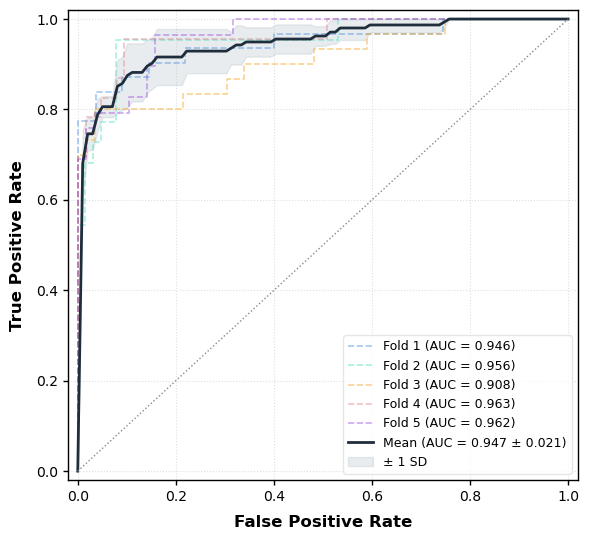

Saved ROC to /media/sdc1/25yhlu/proj/fullcode/AOJ/notebooks/result/AGMU/roc_5fold.svg


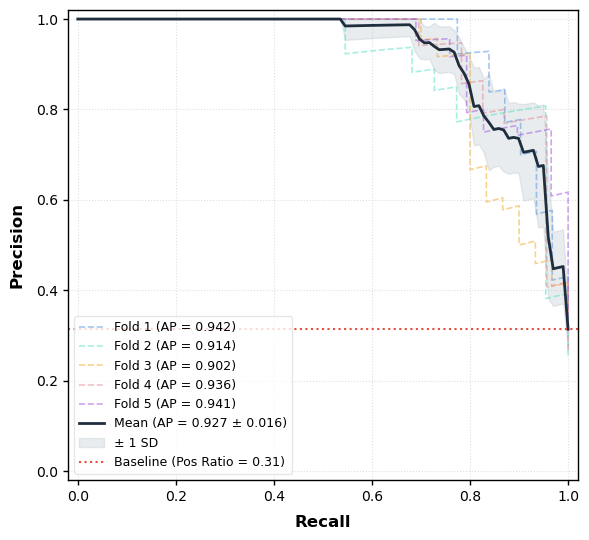

Saved PR to /media/sdc1/25yhlu/proj/fullcode/AOJ/notebooks/result/AGMU/pr_5fold.svg


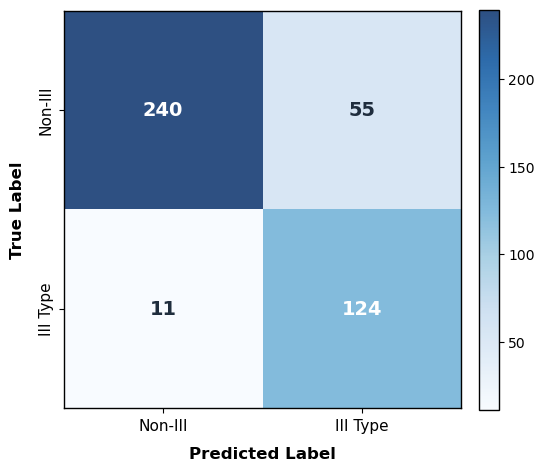

Saved Confusion Matrix to /media/sdc1/25yhlu/proj/fullcode/AOJ/notebooks/result/AGMU/cm_total.png

结果已保存到 5fold_results.pkl


In [32]:
#!/usr/bin/env python3
"""
5-Fold MedicalGMU 统一评估脚本
- 固定阈值 0.25（部署阈值）
- 绘制平均 ROC / PR 曲线
- 绘制合并混淆矩阵
"""

import os
import pickle
import warnings
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
	roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
	confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 中文字体（如有需要）
rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
rcParams['axes.unicode_minus'] = False

# ========== 配置 ==========
# CONFIG = {
# 	'pkl_path': './clinical.pkl',
# 	'image_root': image_root,
# 	'checkpoint_dir': './age/MedGMU_checkpoints13/run_6',  # 你的5个pt文件目录
# 	'img_size': 224,
# 	'batch_size': 8,
# 	'threshold': 0.25,          # 统一部署阈值
# 	'num_folds': 5,
# 	'seed': 42,
# 	'device': 'cuda' if torch.cuda.is_available() else 'cpu',
# 	'dropout': 0.4,

# }


def main_evaluate_5fold():
	print("=" * 60)
	print("5-Fold MedicalGMU 统一评估")
	print(f"统一阈值: {CONFIG['threshold']}")
	print("=" * 60)

	# 获取所有病人ID（与训练时完全一致）
	all_pids = sorted([p.name for p in Path(CONFIG['image_root']).iterdir() if p.is_dir()])
	print(f"总病人: {len(all_pids)}")



	
	# ========== 推荐：从训练时保存的 fold_indices.pkl 加载 ==========
	# 如果你训练时没保存，现在需要手动重建（确保 random_state 和顺序一致）
	
	fold_results = {}      # {fold_idx: (labels, probs)}
	all_fold_metrics = []  # 列表存每折指标
	all_labels_total = []
	all_preds_total = []
	kf = KFold(n_splits=5, shuffle=True, random_state=42)
	fold_results = {}
	all_metrics = []
	all_acc = []
	all_loss = []

	for fold_idx, (train_idx, val_idx) in enumerate(kf.split(all_pids)):
		ckpt_path = os.path.join(CONFIG['checkpoint_dir'], f'fold_{fold_idx+1}_medicalgmu_best.pt')
		print(f"\n--- Fold {fold_idx} ---")
		
		# ckpt = torch.load(ckpt_path, map_location=CONFIG['device'])
		ckpt = torch.load(ckpt_path, map_location=CONFIG['device'], weights_only=False)
		# 加载该折的 scaler 和 patient_ids
		scaler = ckpt['scaler']

		val_pids = [all_pids[i] for i in val_idx]
		print(val_pids)
		train_pids = [all_pids[i] for i in train_idx]
		train_ds = ChiariXrayDataset(
		CONFIG['pkl_path'], CONFIG['image_root'], train_pids,
		transform=get_transforms('val'), scaler=scaler, fit_scaler=False
		)
		train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
								shuffle=False, num_workers=4,
								collate_fn=collate_fn, pin_memory=True)



		# 构建验证集
		val_ds = ChiariXrayDataset(
			CONFIG['pkl_path'], CONFIG['image_root'], val_pids,
			transform=get_transforms('val'), scaler=scaler, fit_scaler=False
		)
		val_loader = DataLoader(val_ds, batch_size=CONFIG['batch_size'],
								shuffle=False, num_workers=4,
								collate_fn=collate_fn, pin_memory=True)

		# 加载模型
		model = MedicalGMUNet(num_cont=8, clin_out=16).to(CONFIG['device'])
		model.load_state_dict(ckpt['model_state'])


		metrics, labels,  preds, probs, joint_ids = evaluate_joint_level(
			model, val_loader, CONFIG['device'], search_threshold= False,best_t =CONFIG['threshold']
		)
		# metrics, labels,  preds, probs = evaluate(
		# 	model, val_loader, CONFIG['device'],CONFIG['threshold']
		# )
		# metrics, labels,  preds, probs = evaluate_patient_level(
		# 	model, val_loader, CONFIG['device'],CONFIG['threshold']
		# )
		best_thresh = metrics['threshold']
		print(best_thresh)
		
		all_fold_metrics.append(metrics)
		fold_results[fold_idx] = (labels, probs, joint_ids)
		# fold_results.append((labels, probs))
		all_labels_total.extend(labels)
		all_preds_total.extend(preds)

		print(f"  AUC: {metrics['auc']:.3f} | AP: {metrics['ap']:.3f}")
		print(f"  Acc: {metrics['accuracy']:.3f} | Sen: {metrics['sensitivity']:.3f} | "
				f"Spe: {metrics['specificity']:.3f} | Pr:{metrics['precision']:.3f}")
		print(f"  PPV: {metrics['ppv']:.3f} | NPV: {metrics['npv']:.3f} | "
				f"F1: {metrics['f1']:.3f}")
		print(f"  TP={metrics['tp']} FP={metrics['fp']} TN={metrics['tn']} FN={metrics['fn']}")

	# ========== 汇总表格 ==========
	print("\n" + "=" * 60)
	print(f"5-Fold 汇总 (Threshold={CONFIG['threshold']})")
	print("=" * 60)
	
	keys = ['auc', 'ap', 'accuracy', 'sensitivity', 'specificity', 'precision','ppv', 'npv', 'f1']
	print(f"{'Metric':<<15} " + " ".join([f"F{i:<7}" for i in range(1, 6)]) + " Mean±Std")
	for k in keys:
		vals = [m[k] for m in all_fold_metrics]
		mean = np.mean(vals)
		std = np.std(vals)
		print(f"{k:<15} " + " ".join([f"{v:.3f}  " for v in vals]) + f" {mean:.3f}±{std:.3f}")

	# ========== 绘图 ==========
	plot_roc_curves(fold_results, save_path=CONFIG['checkpoint_dir']/'roc_5fold.svg')
	plot_pr_curves(fold_results, save_path=CONFIG['checkpoint_dir']/'pr_5fold.svg')
	plot_confusion_matrix_total(np.array(all_labels_total), np.array(all_preds_total),
								save_path=CONFIG['checkpoint_dir']/'cm_total.png')
	# fold_results[fold_idx] = (labels, probs, joint_ids)
	# 保存结果
	results = {
		'threshold': CONFIG['threshold'],
		'fold_metrics': all_fold_metrics,
		'fold_results': fold_results,
		'mean': {k: float(np.mean([m[k] for m in all_fold_metrics])) for k in keys},
		'std': {k: float(np.std([m[k] for m in all_fold_metrics])) for k in keys}
	}
	with open(f'{CONFIG["checkpoint_dir"]}/5fold_results.pkl', 'wb') as f:
		pickle.dump(results, f)
	print("\n结果已保存到 5fold_results.pkl")

	# with open(f'{CONFIG["checkpoint_dir"]}/roc_results.pkl', 'wb') as f:
	# 	pickle.dump(fold_results, f)
	# print("\n结果已保存到 roc_results.pkl")

if __name__ == '__main__':
	main_evaluate_5fold()

# 热力图

## 批量热力图

### 路径保存函数

In [37]:
def save_cam_result(combined_img, gt_label, pred_label, prob, sample_name, 
					fold_num, save_root,img_idx ):
	"""
	保存 CAM 结果到指定结构：
	save_root/
	├── 00/                    # 预测为非III型
	│   └── {patient_id}_{side}/
	│       ├── fold{fold_num}_img1.jpg
	│       └── fold{fold_num}_img2.jpg
	└── 01/                    # 预测为III型
		└── {patient_id}_{side}/
			├── fold{fold_num}_img1.jpg
			└── fold{fold_num}_img2.jpg
	"""
	# 按预测标签分文件夹
	pred_folder = '01' if gt_label == 1 else '00'
	
	# 关节级文件夹名
	save_dir = Path(save_root) / pred_folder / sample_name
	save_dir.mkdir(parents=True, exist_ok=True)
	
	# 文件名：fold{num}_prob{prob}_img{idx}.jpg
	# 需要外部传入当前是该关节的第几张图
	ext = ".jpg"
	base_name  = f"fold{fold_num}_num{img_idx}_pred{pred_label}_prob{prob:.3f}"
	save_path = save_dir / f'{base_name}{ext}' 
	counter = 1
	while save_path.exists():
		save_path = save_dir / f"{base_name}_{counter}{ext}"
		counter += 1
	cv2.imwrite(str(save_path), cv2.cvtColor(combined_img, cv2.COLOR_RGB2BGR))
	return save_path

### CAM包装类

In [36]:
class ManualGradCAM:
	"""
	手动 Grad-CAM：支持多输入模型（影像 + 临床表格），适配 CE 多分类
	"""
	def __init__(self, model, target_layer='resnet.layer3'):
		self.model = model
		self.model.eval()
		self.target_layer = target_layer
		
		for param in self.model.parameters():
			param.requires_grad = True
		
		self.gradients = None
		self.activations = None
		self._register_hook()
	
	def _register_hook(self):
		target_module = None
		for name, module in self.model.named_modules():
			if name == self.target_layer:
				target_module = module
				break
		
		if target_module is None:
			raise ValueError(f"Layer {self.target_layer} not found")
		
		target_module.register_forward_hook(self._forward_hook)
		target_module.register_full_backward_hook(self._backward_hook)
		print(f"[GradCAM] Hook registered on {self.target_layer}")
	
	def _forward_hook(self, module, input, output):
		self.activations = output.detach()
	
	def _backward_hook(self, module, grad_input, grad_output):
		self.gradients = grad_output[0].detach()
	
	def generate(self, img_tensor, cat_features, cont_features, target_class=None):
		"""
		生成 Grad-CAM（CE 多分类版本）
		
		Args:
			img_tensor: [1, C, H, W] 预处理后的影像
			cat_features: dict of [1] LongTensor 分类特征
			cont_features: [1, num_cont] FloatTensor 连续特征
			target_class: int, 目标类别索引。若为 None，则使用预测类别
		
		Returns:
			cam: [H, W] numpy 热力图，归一化到 0~1
			probs: [num_classes] numpy 各类别概率
			pred_class: int 预测类别
		"""
		device = next(self.model.parameters()).device
		
		img_tensor = img_tensor.to(device).requires_grad_(True)
		cat_features = {k: v.to(device) for k, v in cat_features.items()}
		cont_features = cont_features.to(device)
		
		self.model.zero_grad()
		logits = self.model(img_tensor, cat_features, cont_features)  # [1, num_classes]
		
		# ===== 1. CE 多分类：计算所有类别概率 =====
		probs = torch.softmax(logits, dim=1)[0].detach().cpu().numpy()  # [num_classes]
		pred_class = int(torch.argmax(logits, dim=1).item())
		
		# 若未指定目标类别，默认使用预测类别
		if target_class is None:
			target_class = pred_class
		
		# ===== 2. 反向传播：对目标类别 score 求梯度 =====
		score = logits[0, target_class]
		score.backward()
		
		if self.gradients is None:
			raise RuntimeError("Backward hook failed to capture gradients")
		if self.activations is None:
			raise RuntimeError("Forward hook failed to capture activations")
		
		# ===== 3. Grad-CAM 核心计算（不变）=====
		weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)  # [1, C, 1, 1]
		cam = torch.sum(weights * self.activations, dim=1)  # [1, H, W]
		cam = F.relu(cam)
		
		cam = cam - cam.min()
		cam = cam / (cam.max() + 1e-8)
		
		cam = F.interpolate(
			cam.unsqueeze(0), 
			size=(img_tensor.size(2), img_tensor.size(3)),
			mode='bilinear',
			align_corners=False
		)
		
		return cam.squeeze().cpu().numpy(), probs, pred_class

### 拼接函数 Overlay

In [35]:
def concatenate_images_with_gap(images, gap=5, gap_color=(255, 255, 255)):
	"""
	水平拼接多张图，中间留白色 gap
	"""
	# 统一高度（以第一张图为基准）
	target_h = images[0].shape[0]
	resized = []
	for img in images:
		if img.shape[0] != target_h:
			ratio = target_h / img.shape[0]
			new_w = int(img.shape[1] * ratio)
			img = cv2.resize(img, (new_w, target_h))
		resized.append(img)
	
	# 计算总宽度
	total_width = sum(img.shape[1] for img in resized) + gap * (len(resized) - 1)
	result = np.full((target_h, total_width, 3), gap_color, dtype=np.uint8)
	
	# 逐个粘贴
	x_offset = 0
	for img in resized:
		result[:, x_offset:x_offset + img.shape[1]] = img
		x_offset += img.shape[1] + gap
	
	return result


In [34]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


def create_colorful_overlay(
	img_np, 
	cam_resized, 
	threshold=0.05,
	alpha=0.7,
	colormap_style='turbo',    # 彩虹色：蓝→青→绿→黄→红
	smooth_sigma=2.0,
):
	"""
	彩色热力图叠加原图
	"""
	# 统一转成 0-1 float
	if img_np.max() > 1.5:
		img_np = img_np.astype(np.float32) / 255.0
	else:
		img_np = img_np.astype(np.float32)
	
	# 高斯平滑 CAM
	cam_smooth = cv2.GaussianBlur(cam_resized.astype(np.float32), (0, 0), smooth_sigma)
	if cam_smooth.max() > 0:
		cam_smooth = cam_smooth / cam_smooth.max()
	
	# 软 mask：低阈值让更多区域染色
	mask = np.clip((cam_smooth - threshold) / 0.2, 0, 1)
	mask = cv2.GaussianBlur(mask, (0, 0), 1.0)
	
	# 生成彩色热力图（0-1 范围）
	cmap = plt.get_cmap(colormap_style)
	heatmap = cmap(cam_smooth)[:, :, :3].astype(np.float32)
	
	# 叠加：原图压暗 + 彩色热力图
	mask_3ch = mask[:, :, None]
	img_darker = img_np * 0.4  # 原图压暗 60%，让彩色更突出
	
	overlay = img_darker * (1 - mask_3ch * alpha) + heatmap * (mask_3ch * alpha)
	overlay = np.clip(overlay, 0, 1)
	
	return (overlay * 255).astype(np.uint8), cam_smooth


def create_multi_threshold_colorful(
	img_np, 
	cam_resized,
	thresholds=[0.05, 0.2, 0.4],
	alpha=0.7,
	gap=5,
	colormap_style='turbo',
):
	"""
	多阈值彩色对比图
	"""
	# 原图
	if img_np.max() <= 1.0:
		original = (img_np * 255).astype(np.uint8)
	else:
		original = img_np.astype(np.uint8)
	
	if len(original.shape) == 2:
		original = np.stack([original] * 3, axis=-1)
	
	images = [original]
	for th in thresholds:
		overlay, _ = create_colorful_overlay(
			img_np, cam_resized, th, alpha, colormap_style
		)
		images.append(overlay)
	
	return concatenate_images_with_gap(images, gap=gap)

In [41]:

def generate_cams_for_fold(model, val_loader, fold_idx, save_root,
						   target_class=1, device='cuda',
						   cam_threshold=0.2,
						   overlay_alpha=0.6):
	"""
	只需改一行：create_multi_threshold_figure -> create_multi_threshold_figure_v2
	"""
	# save_dir = save_root / f'fold{fold_idx}'
	# save_dir.mkdir(parents=True, exist_ok=True)
	
	cam_generator = ManualGradCAM(model, target_layer='resnet.layer4')
	
	results = []
	joint_counter = defaultdict(int)
	
	for batch_idx, (imgs, labels, cat_batch, cont_batch, _, joint_ids) in enumerate(val_loader):
		img_tensor = imgs.to(device)
		gt_label = labels[0].item()
		joint_id = joint_ids[0]
		
		cat_features = {k: v[0:1].to(device) for k, v in cat_batch.items()}
		cont_features = cont_batch[0:1].to(device)
		
		with torch.no_grad():
			logits = model(img_tensor, cat_features, cont_features)
			# probs = torch.softmax(logits, dim=1)
			# prob = probs[0, 1].item()
			# pred_label = 1 if prob >= CONFIG['threshold'] else 0
			probs = torch.softmax(logits, dim=1)[0]
			pred_label = int(torch.argmax(probs).item())
			pred_prob = probs[pred_label].item()
		
		try:
			cam, _, _ = cam_generator.generate(
				img_tensor, cat_features, cont_features, target_class=pred_label
			)
			
			# 反归一化原图
			img_np = imgs[0].cpu().numpy().transpose(1, 2, 0)
			mean = np.array([0.485, 0.456, 0.406])
			std = np.array([0.229, 0.224, 0.225])
			img_np = img_np * std + mean
			img_np = np.clip(img_np, 0, 1)
			h, w = img_np.shape[:2]
			
			cam_resized = cv2.resize(cam, (w, h))
			
			# ===== 改这里：用 v2 版本 =====
			combined_img = create_multi_threshold_colorful(
				img_np,
				cam_resized,
				thresholds=[0.05, 0.4, 0.6],
				alpha=0.5,                    # 略降透明度
				gap=5,
				colormap_style='turbo'        # 或 'hot', 'plasma', 'turbo'
			)
			
			joint_counter[joint_id] += 1
			img_idx = joint_counter[joint_id]
			sample_name = f'{joint_id}'
			save_path = save_cam_result(
				combined_img=combined_img,
				gt_label=gt_label,
				pred_label=pred_label,
				prob=pred_prob,
				sample_name=sample_name,
				fold_num=fold_idx,
				save_root=save_root,
				img_idx=img_idx
			)
			
		except Exception as e:
			print(f"  Failed for {joint_id}: {e}")
			import traceback
			traceback.print_exc()
	
	# print(f"Fold {fold_idx} complete: {len(results)} CAMs saved to {save_dir}")
	return results

### 运行

In [42]:
#!/usr/bin/env python3
"""
手动 Grad-CAM 实现 - 兼容 MedicalGMUNet
无需 pytorch-grad-cam 库
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import cv2
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

all_pids = sorted([p.name for p in Path(CONFIG['image_root']).iterdir() if p.is_dir()])
print(f"总病人: {len(all_pids)}")
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(all_pids)):
	print(f"\n--- Fold {fold_idx} ---")
	
	# 加载 checkpoint
	ckpt_path = Path(CONFIG['checkpoint_dir']) / f"fold_{fold_idx+1}_medicalgmu_best.pt"
	if not ckpt_path.exists():
		print(f"  Skip: {ckpt_path} not found")
		continue
		
	ckpt = torch.load(ckpt_path, map_location=CONFIG['device'], weights_only=False)

	# 构建 Dataset
	# 注意：需要训练集的 scaler，这里简化处理，实际应从 ckpt 加载
	# 假设 ckpt 里有 scaler
	train_pids = [all_pids[i] for i in train_idx]
	val_pids = [all_pids[i] for i in val_idx]
	scaler = ckpt.get('scaler', None)
	train_ds = ChiariXrayDataset(
		CONFIG['pkl_path'], CONFIG['image_root'], train_pids,
		transform=get_transforms('train'), fit_scaler=True
	)
	val_ds = ChiariXrayDataset(
		CONFIG['pkl_path'], CONFIG['image_root'], val_pids,
		transform=get_transforms('val'), scaler=scaler, fit_scaler=False
	)
	val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, 
							collate_fn=collate_fn, num_workers=2)
	
	# 加载模型
	model = MedicalGMUNet(num_cont=8, clin_out=16).to(CONFIG['device'])
	model.load_state_dict(ckpt['model_state'])
	model.eval()
	results = generate_cams_for_fold(model, val_loader, fold_idx=fold_idx, 
									save_root=CONFIG['checkpoint_dir'], device='cuda')

总病人: 215

--- Fold 0 ---
215
[Dataset] 病人: 172, 影像: 2533, 正类(III型): 720
215
[Dataset] 病人: 43, 影像: 558, 正类(III型): 175
[GradCAM] Hook registered on resnet.layer4

--- Fold 1 ---
215
[Dataset] 病人: 172, 影像: 2456, 正类(III型): 774
215
[Dataset] 病人: 43, 影像: 635, 正类(III型): 121
[GradCAM] Hook registered on resnet.layer4

--- Fold 2 ---
215
[Dataset] 病人: 172, 影像: 2477, 正类(III型): 692
215
[Dataset] 病人: 43, 影像: 614, 正类(III型): 203
[GradCAM] Hook registered on resnet.layer4

--- Fold 3 ---
215
[Dataset] 病人: 172, 影像: 2387, 正类(III型): 677
215
[Dataset] 病人: 43, 影像: 704, 正类(III型): 218
[GradCAM] Hook registered on resnet.layer4

--- Fold 4 ---
215
[Dataset] 病人: 172, 影像: 2511, 正类(III型): 717
215
[Dataset] 病人: 43, 影像: 580, 正类(III型): 178
[GradCAM] Hook registered on resnet.layer4
